In [3]:
import specpolFlow as pol
import matplotlib.pyplot as plt
import VPtools as vp
import numpy as np
from pathlib import Path
import math
from matplotlib.gridspec import GridSpec
path_google = 'G:/Shared drives/'
obs_folder = Path(r"G:\Shared drives\BinamicsOstars\DataFromEve\spectra_tovero")
# import normPlot
import pandas as pd


In [5]:
hd = "hd191201"    

obs = sorted([f.name for f in obs_folder.glob(f"{hd}*.s")])

print(f"Found {len(obs)} observations for {hd}:")
for f in obs:
    print(f)
print(obs)

filename1 = obs[0]
filename2 = obs[1]

spec1 = pol.read_spectrum(obs_folder / filename1)
spec1 = spec1.merge_orders(mode="trim")
# spec2 = pol.read_spectrum(obs_folder / filename2)
# spec2 = spec2.merge_orders(mode="trim")

label1 = filename1.replace("_rn.s", "")
# label2 = filename2.replace("_rn.s", "")
spec = spec1
name = filename1

Found 2 observations for hd191201:
hd191201_E_1308737pn_rn.s
hd191201_E_1720107pnm_rn.s
['hd191201_E_1308737pn_rn.s', 'hd191201_E_1720107pnm_rn.s']


Make LSD line profiles

In [ ]:
VALD_file_name = 'LongList_T30000G375.dat'
file_output = 'T30000_depth0.01.mask'
mask = pol.make_mask(VALD_file_name, outMaskName = file_output, 
                     depthCutoff = 0.01, atomsOnly = True)

velrange = 600.0

excluded_regions = (
    pol.get_Balmer_regions_default(velrange)
    + pol.get_telluric_regions_default()
)


mask_clean = mask.clean(excluded_regions)
mask_clean.save(r"T30000G375_depth0.01_clean.mask")



missing Lande factors for 185 lines (skipped) from:
[np.str_('He 2'), np.str_('O 2')]
skipped all lines for species:
[np.str_('H 1')]


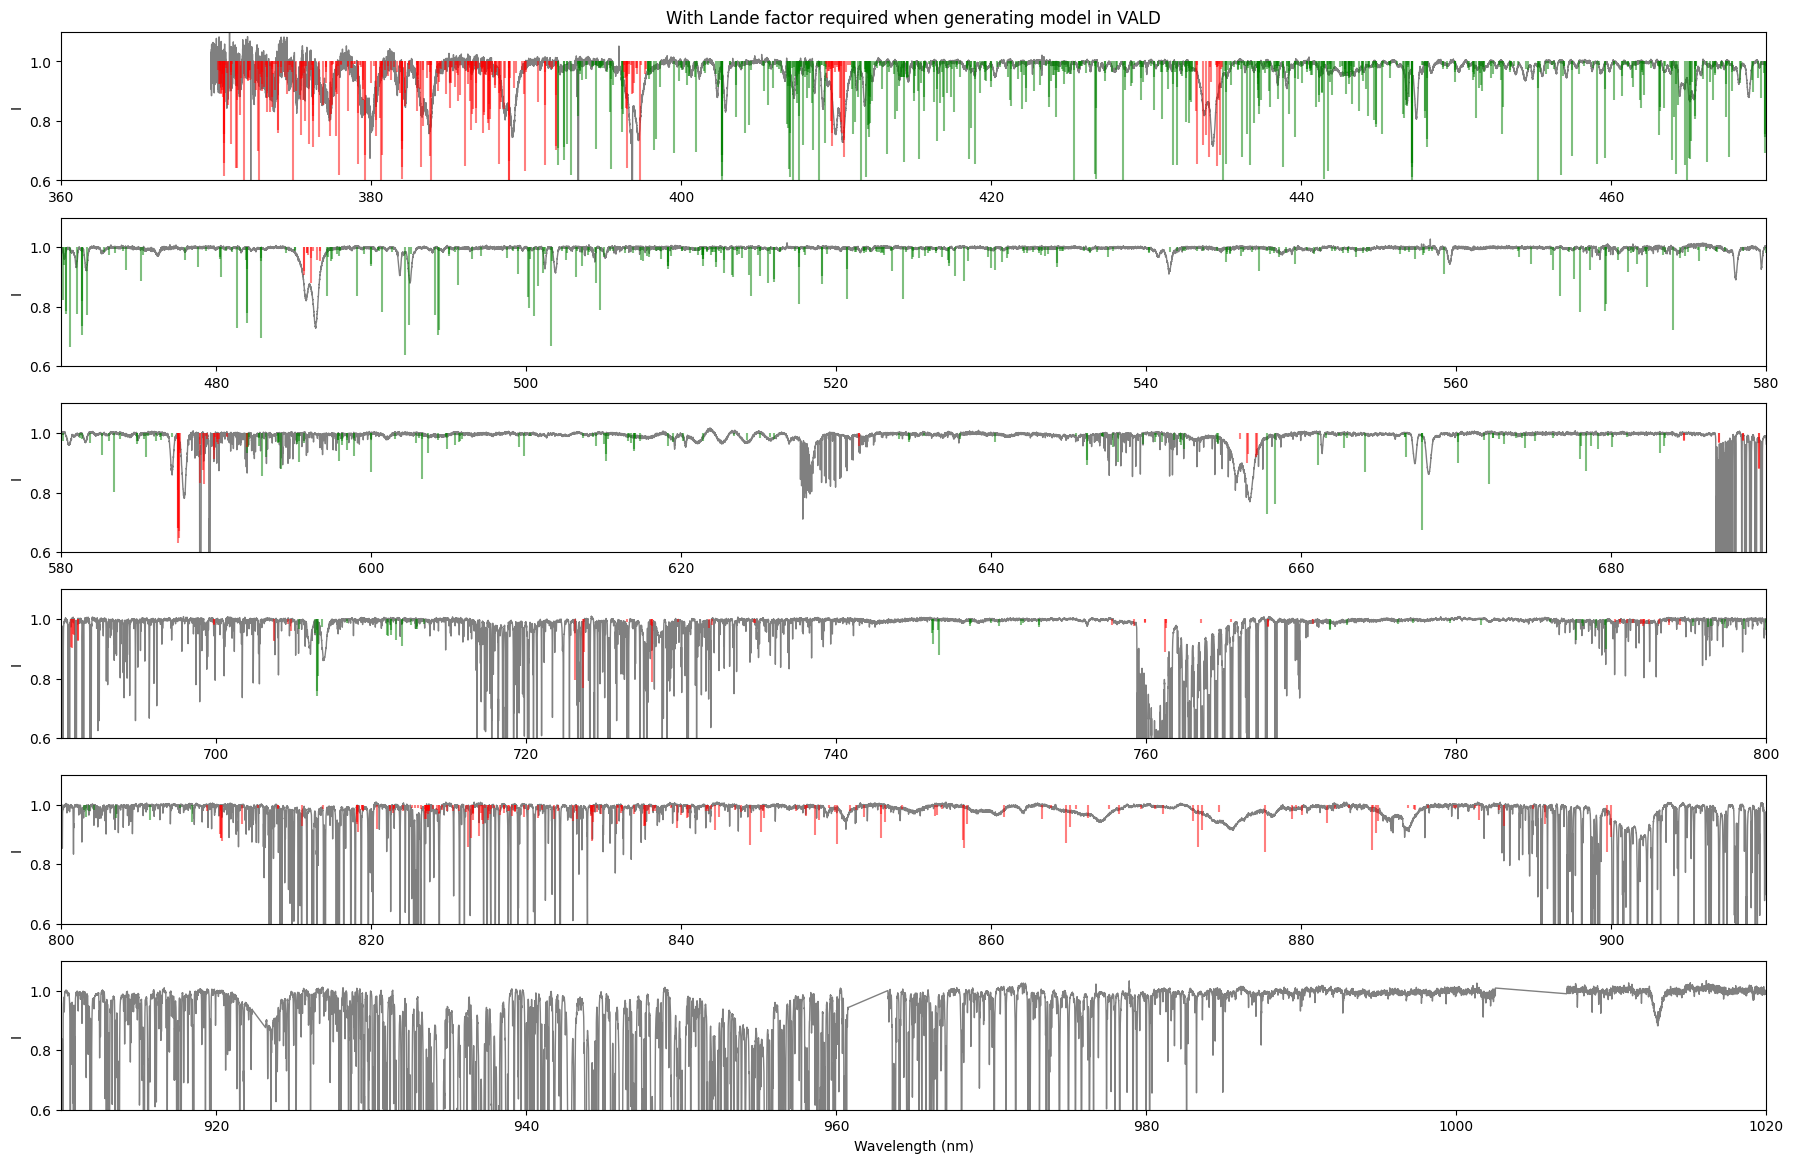

number of lines are 1812


In [ ]:
# mask_clean = pol.read_mask("T30000G375_depth0.01_clean.mask")

# windows_mask = [
#     (360, 470),
#     (470, 580),
#     (580, 690),
#     (690, 800),
#     (800, 910),
#     (910, 1020),
#     (1020, 1100)
# ]


# fig, axes = plt.subplots(6, 1, figsize=(22, 14))

# for ax, (xmin, xmax) in zip(axes, windows_mask):

#     ax.plot(spec1.wl, spec1.specI, color="0.5", lw=1)

#     used = np.where(mask_clean.iuse == 1)
#     unused = np.where(mask_clean.iuse == 0)

#     ax.vlines(mask_clean.wl[used], 1-mask_clean.depth[used], 1,
#               color="g", alpha=0.5)

#     ax.vlines(mask_clean.wl[unused], 1-mask_clean.depth[unused], 1,
#               color="r", alpha=0.5)

#     ax.set_xlim(xmin, xmax)
#     ax.set_ylim(0.6, 1.1)
#     ax.set_ylabel("I")

# axes[-1].set_xlabel("Wavelength (nm)")
# axes[0].set_title("With Lande factor required when generating model in VALD")
# plt.subplots_adjust(hspace=0.25)
# plt.show()
# print("number of lines are {}".format(len(mask_clean.wl)))

In [6]:
# Line mask tweaking
mask_clean='T30000G375_depth0.01_clean.mask' #path of the cleaned mask
# mask_tweaked='T30000G375_depth0.01_cleantweaked.mask' #path of the new tweaked mask
sfile = obs_folder/filename1
# print(sfile)


Modified line mask, removed 153 too closely spaced lines
Average observed spec velocity spacing: 1.806632 km/s
using a 116 point profile with 7.000000 km/s pixels
mean mask depth 0.081543 wl 498.864 Lande 1.171177 (from 1024 lines)
mean mask norm weightI 0.407715 weightV 0.382674
saving model spectrum to  ...
I reduced chi2 259.9248 (chi2 32137366.10 constraints 123757 dof 116)
 Rescaling error bars by: 16.122184
V reduced chi2 1.2082 (chi2 149382.55 constraints 123757 dof 116)
 Rescaling error bars by: 1.099180
 removing profile continuum pol: -5.1144e-06 +/- 2.3616e-09 (avg err 4.8522e-05)
N1 reduced chi2 1.2141 (chi2 150118.28 constraints 123757 dof 116)
 Rescaling error bars by: 1.101883
 removing profile continuum pol: -4.5437e-06 +/- 2.3733e-09 (avg err 4.8642e-05)
(possible Stokes I uncertainty underestimate 1.9816e-03 vs 7.2554e-04)
line range estimate -232.0 230.0 km/s
V in line reduced chi^2 0.889835 (chi2  16.017031) 
 detect prob 0.408641 (fap 5.913587e-01)
 Non-detection V

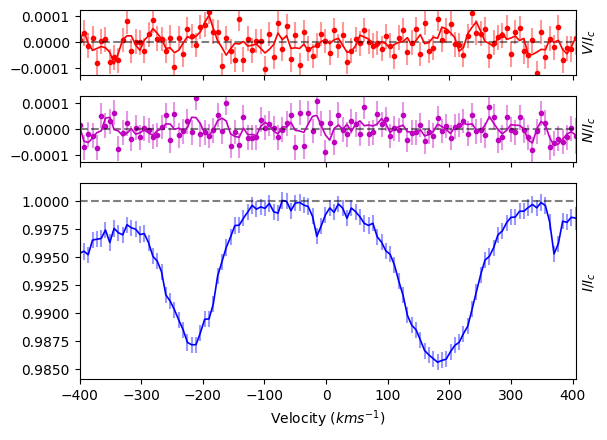

In [12]:
# Calculate LSD 
# clean_Mask_filename = 'T30000G375_depth0.01_cleantweaked.mask'
LSD_outfile = 'lsdoutputsHD191201/hd191201_E_1308737pn_vp7.lsd'
lsd, mod = pol.run_lsdpy(obs = sfile, mask = mask_clean, outLSDName = LSD_outfile, 
           velStart = -400, velEnd = 400.0, velPixel =7,  # number of points / vsini
           normDepth = 0.2, normLande = 1.2, normWave = 500.0)
# figure out what are the lines in Stoke V and Null profiles

{'V bz (G)': np.float64(-24.762441251302718), 'V bz sig (G)': np.float64(119.00723050171428), 'V FAP': np.float64(0.16877265490251414), 'N1 bz (G)': np.float64(-52.50930866872124), 'N1 bz sig (G)': np.float64(119.30816538874411), 'N1 FAP': np.float64(0.6213168062909), 'N2 bz (G)': 0.0, 'N2 bz sig (G)': 0.0, 'N2 FAP': 0.0, 'norm_method': 'auto', 'norm': np.float64(0.9974577), 'cog_method': 'I', 'cog': np.float64(-228.4800751831874), 'int. range start': np.float64(-318.4800751831874), 'int. range end': np.float64(-138.4800751831874)}


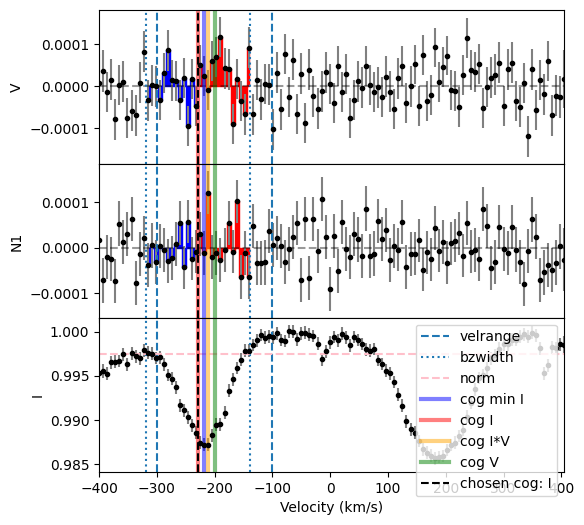

In [14]:
LSD_outfile = "lsdoutputsHD191201/hd191201_E_1308737pn_vp7.lsd"
lsd = pol.read_lsd(LSD_outfile)

Bz_left, fig_left = lsd.calc_bz(cog='I', norm='auto', velrange=[-300, -100], bzwidth=90,
                          lambda0=500.0, geff=1.2, plot=True, figsize=(6,6))
print(Bz_left)


In [ ]:
# testing bzwidth
for width in [60, 70, 80, 90, 100]:
    Bz = lsd.calc_bz(cog='I', norm='auto', velrange=[-300,-100], bzwidth=width,
                          lambda0=500.0, geff=1.2, plot=False)
    print(f"width={width}: Bz={Bz['V bz (G)']:.1f} ± {Bz['V bz sig (G)']:.1f} G, FAP={Bz['V FAP']:.3g}")

width=60: Bz=-56.4 ± 68.2 G, FAP=0.143
width=70: Bz=-35.0 ± 78.9 G, FAP=0.188
width=80: Bz=-38.3 ± 90.9 G, FAP=0.235
width=90: Bz=-24.8 ± 119.0 G, FAP=0.169
width=100: Bz=-9.1 ± 135.0 G, FAP=0.106


In [21]:
folder = Path('lsdoutputsHD191201')

for vp in ['default', 'vp1', 'vp4', 'vp7', 'vp10', 'vp15']:
    lsd = pol.read_lsd(str(folder / f'hd191201_E_1308737pn_{vp}.lsd'))
    Bz= lsd.calc_bz(cog='I', norm='auto', velrange=[-300,-100], bzwidth=80,
                     lambda0=500.0, geff=1.2, plot=False)
    print(f"{vp}: Bz={Bz['V bz (G)']:.1f} ± {Bz['V bz sig (G)']:.1f} G, FAP={Bz['V FAP']:.3g}")

default: Bz=27.2 ± 146.0 G, FAP=0.25
vp1: Bz=23.7 ± 157.9 G, FAP=0.503
vp4: Bz=30.5 ± 140.0 G, FAP=0.148
vp7: Bz=-38.3 ± 90.9 G, FAP=0.235
vp10: Bz=76.1 ± 118.9 G, FAP=0.00775
vp15: Bz=35.5 ± 104.6 G, FAP=0.000289
